In [1]:
import rustworkx as rx
import numpy as np
from rustworkx.visualization import mpl_draw as draw_graph

np.random.seed(0)
# Parameters
n = 100  # Number of nodes
edge_prob = 0.25  # Probability of edge between any pair of nodes

# Generate a random adjacency matrix (symmetric, no self-loops)
adj_matrix = np.triu((np.random.rand(n, n) < edge_prob).astype(float), 1)
adj_matrix += adj_matrix.T  # Make symmetric
# adj_matrix

In [2]:
graph = rx.PyGraph.from_adjacency_matrix(adj_matrix)
# draw_graph(graph, node_size=600, with_labels=True)

In [3]:
import networkx as nx

graph_nx = nx.from_numpy_array(adj_matrix)
cut_value, partition = nx.algorithms.approximation.maxcut.one_exchange(graph_nx)
print("Cut value:", cut_value)

Cut value: 737


In [4]:
def evaluate_cut(graph, bitstring: str) -> float:
    cut_value = 0.0
    for u, v, weight in graph.weighted_edge_list():
        if bitstring[u] != bitstring[v]:  # Nodes are in different partitions
            cut_value += weight
    return cut_value

In [5]:
import matplotlib.pyplot as plt

def draw_graph_cut(G, x):
    colors = []
    for i in range(n):
        if x[i] == '0' or x[i] == 0:
            colors.append("tab:grey") 
        else:
            colors.append("tab:purple") 
    pos, default_axes = rx.spring_layout(G, seed=0), plt.axes(frameon=True)
    rx.visualization.mpl_draw(G, node_color=colors, node_size=600, alpha=0.8, pos=pos, with_labels=True)

In [6]:
# import itertools

# def maxcut_brute_force(graph):
#     n = graph.num_nodes()
#     max_value = float('-inf')
#     best_cut = None

#     # Iterate over all possible bitstrings of length n
#     for bits in itertools.product("01", repeat=n):
#         bitstring = ''.join(bits)
#         value = evaluate_cut(graph, bitstring)
#         if value > max_value:
#             max_value = value
#             best_cut = bitstring

#     return max_value, best_cut

# max_value, best_bitstring = maxcut_brute_force(graph)
# print(f"MaxCut value: {max_value}")
# print(f"Best cut bitstring: {best_bitstring}")
# draw_graph_cut(graph, best_bitstring)

In [7]:
import numpy as np
from scipy.sparse.csgraph import laplacian
from scipy.linalg import eigh

L = laplacian(adj_matrix, normed=True)
# L = laplacian(adj_matrix)

# Compute eigenvectors
vals, vecs = eigh(L)

# Fiedler vector (2nd smallest eigenvalue)
fiedler = vecs[:,n-1]
# print(fiedler)

# Spectral cut: assign bits based on sign
bitstring = (fiedler >= 0).astype(int)
print(bitstring)
print(evaluate_cut(graph, bitstring))
# draw_graph_cut(graph, bitstring)

[0 0 1 1 0 0 1 1 0 1 0 0 0 1 1 0 1 0 0 0 1 0 0 1 0 0 1 1 1 0 1 0 0 0 1 1 0
 0 1 0 1 0 1 1 1 0 1 1 0 0 0 0 1 0 1 0 0 0 1 0 0 1 1 0 1 1 1 1 0 0 1 0 1 1
 1 1 0 0 0 1 1 0 1 0 0 0 0 1 0 0 0 0 1 0 1 0 0 0 0 1]
740.0


In [9]:
fiedler = vecs[:, 1]
fiedler

array([ 0.08855573, -0.06733383,  0.02094196, -0.00628122, -0.03643559,
        0.01522287, -0.10337396,  0.00582148, -0.07420797, -0.05544509,
       -0.04625426,  0.04556864,  0.07139755, -0.08125498, -0.04740859,
        0.15696039,  0.08605884,  0.12856248,  0.15496388,  0.02197676,
       -0.10500408, -0.0755465 , -0.05830194,  0.02345356, -0.03749701,
        0.01492592,  0.08907514,  0.02501836,  0.14774518, -0.1128581 ,
        0.02750855,  0.09160311, -0.16759629,  0.19217669,  0.0765413 ,
       -0.13960741, -0.09409585,  0.07142051, -0.13670656,  0.2140284 ,
        0.07923215, -0.13163797,  0.07177938,  0.17526371, -0.03272234,
       -0.15917305,  0.09435012,  0.03430363,  0.04681369, -0.173252  ,
        0.12233185,  0.07648166, -0.13772051, -0.07652867,  0.13403552,
       -0.01441784, -0.01113765,  0.05653074, -0.05488088, -0.1438372 ,
       -0.07908346,  0.13681449, -0.02470335,  0.0418188 , -0.114566  ,
       -0.10427421, -0.1537297 ,  0.10457957, -0.05168942, -0.05

In [306]:
for i in range(n):
    fiedler_i = vecs[:,i]

    # Spectral cut: assign bits based on sign
    bitstring_i = (fiedler_i >= 0).astype(int)
    print(vals[i], " --> ", evaluate_cut(graph, bitstring_i))

8.881784197001252e-16  -->  0.0
0.38600372547614037  -->  12.0
0.4919605246713272  -->  17.0
0.5404599000448966  -->  16.0
0.6090217192111631  -->  19.0
0.6583458359214961  -->  19.0
0.791435714038102  -->  24.0
0.8291560184097415  -->  22.0
0.9171494386196566  -->  24.0
1.0460887161860937  -->  23.0
1.0509487628702292  -->  25.0
1.1272349705389961  -->  27.0
1.242577376883999  -->  27.0
1.3250432640526766  -->  29.0
1.3333249930031343  -->  29.0
1.4087717167799767  -->  31.0
1.4509861366629697  -->  33.0
1.5346429429974595  -->  32.0
1.619466961730362  -->  34.0
1.6373812819015794  -->  33.0


In [307]:
from qiskit.quantum_info import SparsePauliOp
def build_max_cut_paulis(graph: rx.PyGraph) -> list[tuple[str, float]]:
    # Convert the graph to Pauli list.
    pauli_list = []
    for edge in list(graph.edge_list()):
        paulis = ["I"] * len(graph)
        paulis[edge[0]], paulis[edge[1]] = "Z", "Z"

        weight = graph.get_edge_data(edge[0], edge[1])

        pauli_list.append(("".join(paulis)[::-1], weight))

    return pauli_list


max_cut_paulis = build_max_cut_paulis(graph)

cost_hamiltonian = SparsePauliOp.from_list(max_cut_paulis)
print("Cost Function Hamiltonian:", cost_hamiltonian)

Cost Function Hamiltonian: SparsePauliOp(['IIIIIZIIIIIIIIIIIIIZ', 'IIIIZIIIIIIIIIIIIIIZ', 'IIIZIIIIIIIIIIIIIIIZ', 'IIIIIIIIIIIIIIIZIIZI', 'IIIIIIIIIIIIIZIIIIZI', 'IIIIIZIIIIIIIIIIIIZI', 'IIIIIIIIIIIIIIIIZZII', 'IIIIIIIIIIIIIZIIIZII', 'IIIIIIIIIIIIZIIIIZII', 'IIIIIIZIIIIIIIIIIZII', 'IIIIIZIIIIIIIIIIIZII', 'IIIIZIIIIIIIIIIIIZII', 'ZIIIIIIIIIIIIIIIIZII', 'IIIIIIIIIIIIIIIZZIII', 'IIIIIIIIIIIIZIIIZIII', 'IIIIIIIIIIZIIIIIZIII', 'IIIIZIIIIIIIIIIIZIII', 'IIZIIIIIIIIIIIIIZIII', 'ZIIIIIIIIIIIIIIIZIII', 'IIIIIIIIIIIIZIIZIIII', 'IIIIIIIZIIIIIIIZIIII', 'IIIIZIIIIIIIIIIZIIII', 'IIZIIIIIIIIIIIIZIIII', 'ZIIIIIIIIIIIIIIZIIII', 'IIIIIIIIIIIZIIZIIIII', 'IIIIIIIZIIIIIZIIIIII', 'IIIIIIIIIZIIZIIIIIII', 'IIIIIIIZIIIIZIIIIIII', 'IIIIIZIIIIIIZIIIIIII', 'ZIIIIIIIIIIIZIIIIIII', 'IIIIIIIIIIZZIIIIIIII', 'IIIIIIIIZIIZIIIIIIII', 'IIIIIIIZIIIZIIIIIIII', 'IIIIIIZIIIIZIIIIIIII', 'IIIIZIIIIIIZIIIIIIII', 'ZIIIIIIIIIIZIIIIIIII', 'IIIIIIIIZIZIIIIIIIII', 'IIIIIIIZIIZIIIIIIIII', 'IIIZIIIIIIZIIIIIIIII', 'IZIIIIIIIIZIIIIIIIII'

In [308]:
from qiskit.circuit.library import QAOAAnsatz
from qiskit import QuantumCircuit

init_circuit = QuantumCircuit(n)
# for i, bit in enumerate(reversed(bitstring)):  # reversed due to qubit indexing
for i, bit in enumerate(bitstring):  # reversed due to qubit indexing
    if bit == 1:
        init_circuit.x(i)

reps=5
circuit = QAOAAnsatz(cost_operator=cost_hamiltonian, reps=reps, initial_state=init_circuit)
circuit.measure_all()

# circuit.draw('mpl')

Initialize Params

In [309]:
initial_gamma = np.pi
initial_beta = np.pi/2
init_params = [initial_gamma, initial_beta] * reps

In [310]:
objective_func_vals = [] # Global variable

def cost_func_estimator(params, ansatz, hamiltonian, estimator):

    # transform the observable defined on virtual qubits to
    # an observable defined on all physical qubits
    isa_hamiltonian = hamiltonian.apply_layout(ansatz.layout)

    pub = (ansatz, isa_hamiltonian, params)
    job = estimator.run([pub])

    results = job.result()[0]
    cost = results.data.evs

    objective_func_vals.append(cost)

    return cost

In [311]:
# from qiskit_ibm_runtime import QiskitRuntimeService

# QiskitRuntimeService.save_account(channel="ibm_quantum", token="<MY_IBM_QUANTUM_TOKEN>", overwrite=True, set_as_default=True)
# service = QiskitRuntimeService(channel='ibm_quantum')
# backend = service.least_busy(min_num_qubits=127)
# print(backend)

In [312]:
# from qiskit_ibm_runtime.fake_provider import FakeManilaV2

# backend = FakeManilaV2()

In [313]:
from qiskit_aer import AerSimulator

backend = AerSimulator()

In [314]:
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

pm = generate_preset_pass_manager(backend=backend, optimization_level=3)
candidate_circuit = pm.run(circuit)
# candidate_circuit.draw('mpl')

In [315]:
from qiskit_ibm_runtime import Session, EstimatorV2 as Estimator
from scipy.optimize import minimize

with Session(backend=backend) as session:
    estimator = Estimator(mode=session)
    estimator.options.default_shots = 10000

    # estimator.options.dynamical_decoupling.enable = True
    # estimator.options.dynamical_decoupling.sequence_type = "XY4"
    # estimator.options.twirling.enable_gates = True
    # estimator.options.twirling.num_randomizations = "auto"

    result = minimize(
        cost_func_estimator,
        init_params,
        args=(candidate_circuit, cost_hamiltonian, estimator),
        method="COBYLA",
        tol=1e-2,
    )
    print(result)

 message: Optimization terminated successfully.
 success: True
  status: 1
     fun: -17.9924
       x: [ 3.141e+00  1.573e+00  3.149e+00  1.571e+00  3.147e+00
            1.571e+00  3.142e+00  1.571e+00  3.142e+00  1.571e+00]
    nfev: 51
   maxcv: 0.0


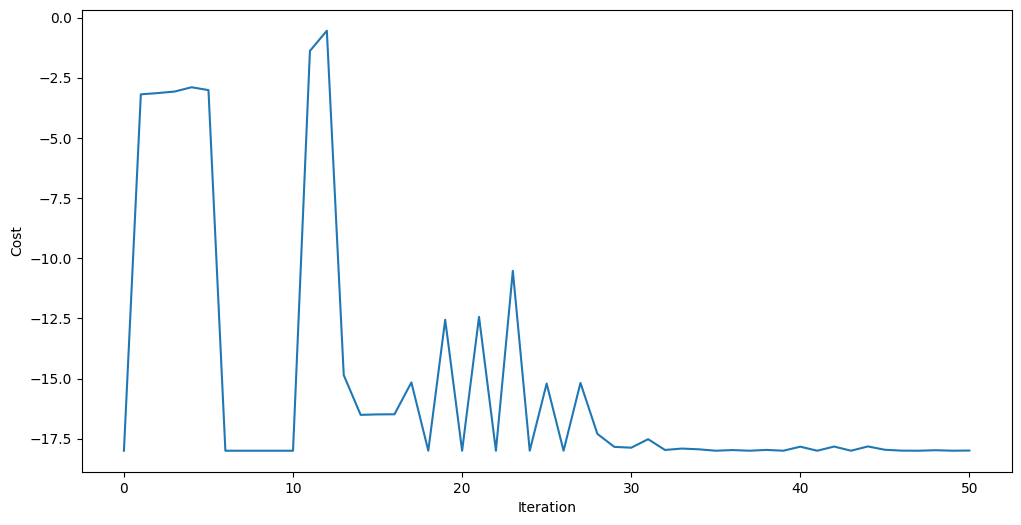

In [316]:
plt.figure(figsize=(12, 6))
plt.plot(objective_func_vals)
plt.xlabel("Iteration")
plt.ylabel("Cost")
plt.show()



In [317]:
optimized_circuit = candidate_circuit.assign_parameters(result.x)
optimized_circuit.draw('mpl', fold=False, idle_wires=False)

In [318]:
from qiskit_ibm_runtime import SamplerV2 as Sampler

sampler = Sampler(mode=backend)
sampler.options.default_shots = 10000

# # Set simple error suppression/mitigation options
# sampler.options.dynamical_decoupling.enable = True
# sampler.options.dynamical_decoupling.sequence_type = "XY4"
# sampler.options.twirling.enable_gates = True
# sampler.options.twirling.num_randomizations = "auto"

pub= (optimized_circuit, )
job = sampler.run([pub], shots=int(1e4))
counts_int = job.result()[0].data.meas.get_int_counts()
counts_bin = job.result()[0].data.meas.get_counts()
shots = sum(counts_int.values())
final_distribution_int = {key: val/shots for key, val in counts_int.items()}
final_distribution_bin = {key: val/shots for key, val in counts_bin.items()}
print(final_distribution_int)

{714481: 0.9991, 718577: 0.0003, 706289: 0.0001, 583409: 0.0002, 713969: 0.0003}


In [319]:
# auxiliary functions to sample most likely bitstring
def to_bitstring(integer, num_bits):
    result = np.binary_repr(integer, width=num_bits)
    return [int(digit) for digit in result]

keys = list(final_distribution_int.keys())
values = list(final_distribution_int.values())
most_likely = keys[np.argmax(np.abs(values))]
most_likely_bitstring = to_bitstring(most_likely, len(graph))
most_likely_bitstring.reverse()

print("Result bitstring:", most_likely_bitstring)

Result bitstring: [1, 0, 0, 0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1, 0, 1]


In [320]:
# import matplotlib.pyplot as plt
# import matplotlib

# matplotlib.rcParams.update({"font.size": 10})
# final_bits = final_distribution_bin
# values = np.abs(list(final_bits.values()))
# top_4_values = sorted(values, reverse=True)[:4]
# positions = []
# for value in top_4_values:
#     positions.append(np.where(values == value)[0])
# fig = plt.figure(figsize=(11, 6))
# ax = fig.add_subplot(1, 1, 1)
# plt.xticks(rotation=45)
# plt.title("Result Distribution")
# plt.xlabel("Bitstrings (reversed)")
# plt.ylabel("Probability")
# ax.bar(list(final_bits.keys()), list(final_bits.values()), color="tab:grey")
# for p in positions:
#     ax.get_children()[int(p)].set_color("tab:purple")
# plt.show()

Cut value = 33.0


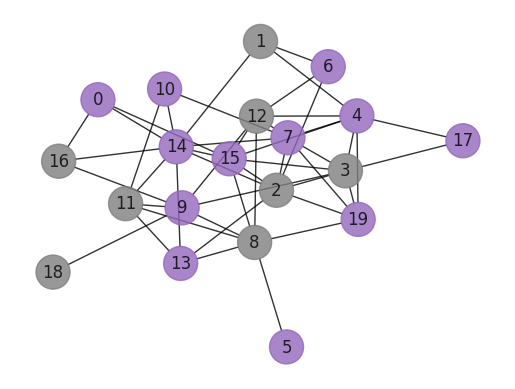

In [321]:
print(f"Cut value = {evaluate_cut(graph, most_likely_bitstring)}")
draw_graph_cut(graph, most_likely_bitstring)